# Predicting the transcriptional response to an unseen gene knockdown

Silencing one gene shifts thousands of others. Given a gene the model has never seen, can its
whole signature be predicted from a description of what the gene is?

Data: [Replogle et al. 2022](https://doi.org/10.1016/j.cell.2022.05.013) genome-wide Perturb-seq
(CRISPRi in K562), pseudobulk. Features from Gene Ontology, STRING v12 and ESM-2.

In [1]:
import gzip
import subprocess
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, diags
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold

DATA, CACHE, FIGS = Path('data'), Path('cache'), Path('figures')
for d in (DATA, CACHE, FIGS):
    d.mkdir(exist_ok=True)

DEVICE = ('cuda' if torch.cuda.is_available()
          else 'mps' if torch.backends.mps.is_available() else 'cpu')
torch.manual_seed(0)
RNG = np.random.RandomState(0)

SOURCES = {
    'K562_essential_normalized_bulk_01.h5ad': 'https://ndownloader.figshare.com/files/35780870',
    'goa_human.gaf.gz': 'https://current.geneontology.org/annotations/goa_human.gaf.gz',
    'string_links.txt.gz': ('https://stringdb-downloads.org/download/protein.links.v12.0/'
                            '9606.protein.links.v12.0.txt.gz'),
    'string_info.txt.gz': ('https://stringdb-downloads.org/download/protein.info.v12.0/'
                           '9606.protein.info.v12.0.txt.gz'),
    'uniprot_human.fasta.gz': ('https://rest.uniprot.org/uniprotkb/stream?format=fasta'
                               '&compressed=true&query=%28organism_id%3A9606%29+AND+%28reviewed%3Atrue%29'),
}

In [2]:
def readable(path):
    """Half-downloaded files are still large, so check the file parses to its end."""
    path = Path(path)
    if not path.exists() or path.stat().st_size < 1e6:
        return False
    try:
        if path.suffix == '.gz':
            with gzip.open(path, 'rb') as f:
                while f.read(1 << 24):
                    pass
        else:
            ad.read_h5ad(path, backed='r').file.close()
        return True
    except Exception:
        return False


for name, url in SOURCES.items():
    if readable(DATA / name):
        continue
    subprocess.run(['curl', '-sL', '-C', '-', url, '-o', str(DATA / name)], check=True)
    if not readable(DATA / name):
        (DATA / name).unlink(missing_ok=True)
        subprocess.run(['curl', '-sL', url, '-o', str(DATA / name)], check=True)
print('\n'.join(f'{n}: {(DATA / n).stat().st_size / 1e6:.0f} MB' for n in SOURCES))

K562_essential_normalized_bulk_01.h5ad: 80 MB
goa_human.gaf.gz: 15 MB
string_links.txt.gz: 83 MB
string_info.txt.gz: 2 MB
uniprot_human.fasta.gz: 8 MB


## The measurements

In [3]:
adata = ad.read_h5ad(DATA / 'K562_essential_normalized_bulk_01.h5ad')
target_of = np.array([n.split('_')[1] for n in adata.obs_names])

responses = pd.DataFrame(adata.X, index=target_of, columns=adata.var.gene_name.values)
responses = responses[responses.index != 'non-targeting'].groupby(level=0).mean()
responses = responses.loc[:, ~responses.columns.duplicated()]

# min p-value per gene: did silencing it actually do anything?
pvalue = (pd.Series(adata.obs.energy_test_p_value.values, index=target_of)
            .groupby(level=0).min())

GENES = responses.index.to_numpy()
Y = responses.to_numpy(np.float32)
MEASURED = responses.columns
COLUMN_OF = {g: i for i, g in enumerate(MEASURED)}
FOLDS = list(KFold(5, shuffle=True, random_state=0).split(GENES))

print(f'{Y.shape[0]} silenced genes x {Y.shape[1]} measured genes')
print(f'{(pvalue[GENES] < 0.05).sum()} with a detectable effect')

2057 silenced genes x 8561 measured genes
1675 with a detectable effect


In [4]:
# sanity check: a ribosomal protein should shut down translation and stress the cell
example = responses.loc['RPL23'].sort_values()
pd.concat([example.head(6), example.tail(6)]).to_frame('change').T.round(2)

,RPL23,MT-ATP6,MT-ND2,MT-ND4,MT-CO3,MT-CO2,AMHR2,DYNLL1,SNHG1,GAS5,FTH1,IGFL2-AS1
change,-2.76,-1.99,-1.96,-1.69,-1.63,-1.47,2.04,2.29,2.53,2.78,2.92,3.04


## Describing a gene

In [5]:
def gene_ontology(genes, n_components=256):
    rows = []
    with gzip.open(DATA / 'goa_human.gaf.gz', 'rt') as f:
        for line in f:
            if line.startswith('!'):
                continue
            fields = line.split('\t')
            if 'NOT' not in fields[3]:
                rows.append((fields[2], fields[4]))

    annotations = pd.DataFrame(rows, columns=['gene', 'term']).drop_duplicates()
    gene_ids = {g: i for i, g in enumerate(sorted(annotations.gene.unique()))}
    term_ids = {t: i for i, t in enumerate(sorted(annotations.term.unique()))}
    matrix = csr_matrix((np.ones(len(annotations)),
                         (annotations.gene.map(gene_ids), annotations.term.map(term_ids))),
                        shape=(len(gene_ids), len(term_ids)))
    # tf-idf so that a rare, specific term counts for more than a universal one
    embedded = TruncatedSVD(n_components, random_state=0).fit_transform(
        TfidfTransformer().fit_transform(matrix))
    return np.array([embedded[gene_ids[g]] if g in gene_ids else np.zeros(n_components)
                     for g in genes])


def string_network(genes, n_components=256, min_score=400):
    info = pd.read_csv(DATA / 'string_info.txt.gz', sep='\t')
    symbol_of = dict(zip(info['#string_protein_id'], info.preferred_name))

    links = pd.read_csv(DATA / 'string_links.txt.gz', sep=' ')
    links = links[links.combined_score >= min_score]
    links = links.assign(a=links.protein1.map(symbol_of),
                         b=links.protein2.map(symbol_of)).dropna(subset=['a', 'b'])

    node_ids = {g: i for i, g in enumerate(sorted(set(links.a) | set(links.b)))}
    adjacency = csr_matrix((links.combined_score.to_numpy() / 1000,
                            (links.a.map(node_ids), links.b.map(node_ids))),
                           shape=(len(node_ids),) * 2)
    # symmetric normalisation, or hub proteins dominate every component
    degree = np.asarray(adjacency.sum(1)).ravel() + 1e-9
    normalised = diags(degree ** -0.5) @ adjacency @ diags(degree ** -0.5)
    embedded = TruncatedSVD(n_components, random_state=0).fit_transform(normalised)
    return np.array([embedded[node_ids[g]] if g in node_ids else np.zeros(n_components)
                     for g in genes])

In [6]:
def esm2_embeddings(genes, window=1000):
    cached = CACHE / 'esm2_650M.npz'
    if not cached.exists():
        import esm

        sequences, name, chunks = {}, None, []
        with gzip.open(DATA / 'uniprot_human.fasta.gz', 'rt') as f:
            for line in f:
                if line.startswith('>'):
                    if name and name not in sequences:
                        sequences[name] = ''.join(chunks)
                    tags = [p for p in line.split() if p.startswith('GN=')]
                    name, chunks = (tags[0][3:] if tags else None), []
                else:
                    chunks.append(line.strip())
        if name and name not in sequences:
            sequences[name] = ''.join(chunks)

        model, alphabet = esm.pretrained.esm2_t33_650M_UR50D()
        model = model.eval().to(DEVICE)
        to_batch = alphabet.get_batch_converter()

        have = [g for g in genes if g in sequences]
        vectors = []
        for gene in have:
            seq = sequences[gene]
            pieces = [seq[i:i + window] for i in range(0, len(seq), window)]
            parts = []
            for piece in pieces:
                _, _, tokens = to_batch([(gene, piece)])
                with torch.no_grad():
                    out = model(tokens.to(DEVICE), repr_layers=[33])
                # drop the start token, keep one vector per residue, then average
                parts.append(out['representations'][33][0, 1:len(piece) + 1].mean(0).cpu().numpy())
            vectors.append(np.average(parts, axis=0, weights=[len(p) for p in pieces]))
        np.savez(cached, genes=np.array(have), embeddings=np.stack(vectors))

    stored = np.load(cached)
    lookup = {g: i for i, g in enumerate(stored['genes'])}
    width = stored['embeddings'].shape[1]
    return np.array([stored['embeddings'][lookup[g]] if g in lookup else np.zeros(width)
                     for g in genes])

In [7]:
GO = gene_ontology(GENES)
STRING = string_network(GENES)
ESM = esm2_embeddings(GENES)
print({'GO': GO.shape, 'STRING': STRING.shape, 'ESM-2': ESM.shape})

{'GO': (2057, 256), 'STRING': (2057, 256), 'ESM-2': (2057, 1280)}


## Models

In [8]:
def standardise(F, train):
    # training genes only; standardising over everything would leak
    return (F - F[train].mean(0)) / (F[train].std(0) + 1e-6)


def annotations(train):
    return np.hstack([standardise(GO, train), standardise(STRING, train)])


def sequence(train):
    return standardise(PCA(128, random_state=0).fit(ESM[train]).transform(ESM), train)


def average_response(train, test):
    return np.repeat(Y[train].mean(0)[None], len(test), 0)


def ridge(describe, alpha=2e4):
    def predict(train, test):
        F, mean = describe(train), Y[train].mean(0)
        # predict the residual: the shared stress response is the same for every gene
        return mean + Ridge(alpha=alpha).fit(F[train], Y[train] - mean).predict(F[test])
    return predict


def neighbours(describe, k=20, temperature=0.1):
    def predict(train, test):
        F = describe(train)
        F = F / (np.linalg.norm(F, axis=1, keepdims=True) + 1e-9)
        mean, out = Y[train].mean(0), []
        for similarity in F[test] @ F[train].T:
            near = np.argsort(-similarity)[:k]
            weights = np.exp(similarity[near] / temperature)
            out.append(mean + (weights / weights.sum()) @ (Y[train][near] - mean))
        return np.array(out)
    return predict


def mlp(describe, n_components=64, hidden=512, epochs=400, patience=60, seed=0):
    def predict(train, test):
        torch.manual_seed(seed)
        F = describe(train).astype(np.float32)
        mean = Y[train].mean(0)
        pca = PCA(n_components, random_state=0).fit(Y[train] - mean)
        targets = pca.transform(Y[train] - mean).astype(np.float32)
        scale = targets.std(0) + 1e-6

        order = np.random.RandomState(seed).permutation(len(train))
        inner, held = order[:int(0.9 * len(order))], order[int(0.9 * len(order)):]
        xt = torch.tensor(F[train][inner]).to(DEVICE)
        yt = torch.tensor(targets[inner] / scale).to(DEVICE)
        xv = torch.tensor(F[train][held]).to(DEVICE)
        yv = torch.tensor(targets[held] / scale).to(DEVICE)

        net = nn.Sequential(nn.Linear(F.shape[1], hidden), nn.GELU(), nn.Dropout(0.3),
                            nn.Linear(hidden, hidden), nn.GELU(), nn.Dropout(0.3),
                            nn.Linear(hidden, n_components)).to(DEVICE)
        optimiser = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-2)

        best, best_state, waited = np.inf, None, 0
        for _ in range(epochs):
            net.train()
            optimiser.zero_grad()
            nn.functional.mse_loss(net(xt), yt).backward()
            optimiser.step()
            net.eval()
            with torch.no_grad():
                loss = nn.functional.mse_loss(net(xv), yv).item()
            if loss < best - 1e-5:
                best, waited = loss, 0
                best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
            else:
                waited += 1
                if waited > patience:
                    break

        net.load_state_dict(best_state)
        net.eval()
        with torch.no_grad():
            predicted = net(torch.tensor(F[test]).to(DEVICE)).cpu().numpy() * scale
        return mean + pca.inverse_transform(predicted)
    return predict


def ensemble(models, weights):
    def predict(train, test):
        return sum(w * m(train, test) for w, m in zip(weights, models))
    return predict

## Scoring

In [9]:
def correlation(a, b):
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-12))


def evaluate(predict):
    rows = []
    for train, test in FOLDS:
        predicted, mean = predict(train, test), Y[train].mean(0)
        for slot, gene_index in enumerate(test):
            gene = GENES[gene_index]
            keep = np.ones(Y.shape[1], bool)    # drop the silenced gene's own column
            if gene in COLUMN_OF:
                keep[COLUMN_OF[gene]] = False
            truth, guess = Y[gene_index][keep], predicted[slot][keep]
            moved = np.argsort(-np.abs(truth))[:50]
            rows.append(dict(gene=gene,
                             all_genes=correlation(guess, truth),
                             top50=correlation(guess[moved], truth[moved]),
                             specific=correlation(guess - mean[keep], truth - mean[keep]),
                             responded=bool(pvalue[gene] < 0.05)))
    return pd.DataFrame(rows)


MODELS = {
    'average response': average_response,
    'sequence only': mlp(sequence),
    'annotations: ridge': ridge(annotations),
    'annotations: neighbours': neighbours(annotations),
    'annotations: neural net': mlp(annotations),
}
MODELS['ensemble'] = ensemble([ridge(annotations), neighbours(annotations), mlp(annotations)],
                              [0.4, 0.2, 0.4])

per_gene = {name: evaluate(predict) for name, predict in MODELS.items()}
summary = pd.DataFrame({
    name: dict(all_genes=df.all_genes.mean(), top50=df.top50.mean(),
               specific=df.specific.mean(),
               specific_responders=df[df.responded].specific.mean())
    for name, df in per_gene.items()}).T
summary.round(3)

,all_genes,top50,specific,specific_responders
average response,0.223,0.425,0.000,0.000
sequence only,0.256,0.465,0.154,0.165
annotations: ridge,0.319,0.542,0.291,0.317
annotations: neighbours,0.318,0.510,0.281,0.323
annotations: neural net,0.330,0.516,0.297,0.321
ensemble,0.345,0.555,0.313,0.344


In [10]:
# does the amino acid sequence add anything the annotations do not already carry?
def everything(train):
    return np.hstack([annotations(train), sequence(train)])

with_sequence = evaluate(ensemble([ridge(everything), neighbours(everything), mlp(everything)],
                                  [0.4, 0.2, 0.4]))
pd.DataFrame({'ensemble': summary.loc['ensemble'],
              'ensemble + ESM-2': dict(all_genes=with_sequence.all_genes.mean(),
                                       top50=with_sequence.top50.mean(),
                                       specific=with_sequence.specific.mean(),
                                       specific_responders=with_sequence[with_sequence.responded].specific.mean())
              }).T.round(3)

,all_genes,top50,specific,specific_responders
ensemble,0.345,0.555,0.313,0.344
ensemble + ESM-2,0.345,0.553,0.314,0.344


## Figures

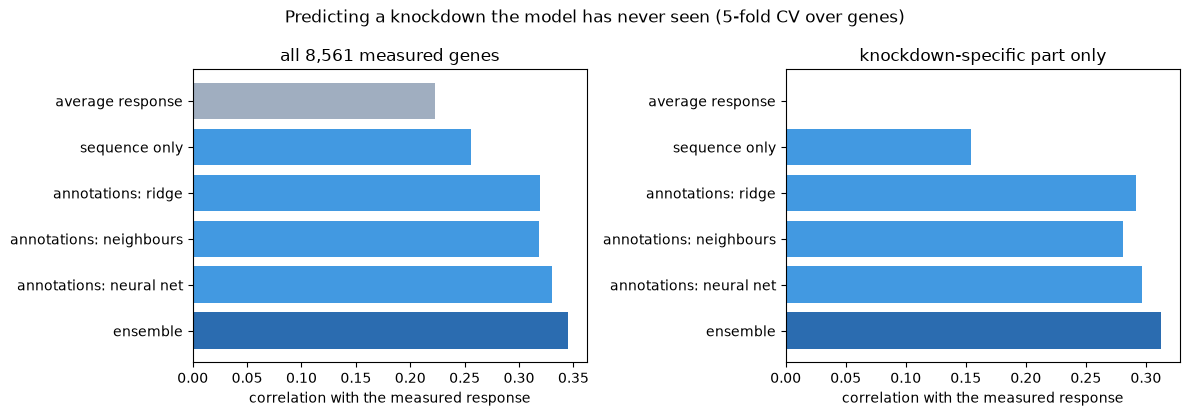

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
names = list(summary.index)
shades = ['#a0aec0' if n == 'average response' else '#2b6cb0' if n == 'ensemble' else '#4299e1'
          for n in names]
for ax, column, title in [(axes[0], 'all_genes', f'all {Y.shape[1]:,} measured genes'),
                          (axes[1], 'specific', 'knockdown-specific part only')]:
    ax.barh(names, summary[column], color=shades)
    ax.invert_yaxis()
    ax.set_xlabel('correlation with the measured response')
    ax.set_title(title)
fig.suptitle('Predicting a knockdown the model has never seen (5-fold CV over genes)')
fig.tight_layout()
fig.savefig(FIGS / 'models.png', dpi=150, bbox_inches='tight')

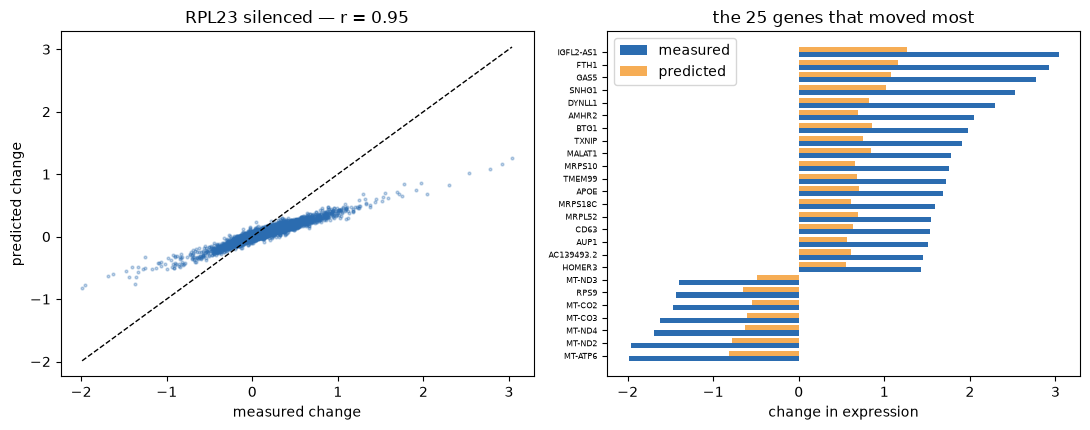

In [12]:
best = per_gene['ensemble'].query('responded').sort_values('specific', ascending=False).iloc[0].gene
index = int(np.flatnonzero(GENES == best)[0])
train, test = next((tr, te) for tr, te in FOLDS if index in te)
predicted = MODELS['ensemble'](train, test)[int(np.flatnonzero(test == index)[0])]

keep = np.ones(Y.shape[1], bool)
keep[COLUMN_OF[best]] = False
truth, guess = Y[index][keep], predicted[keep]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].scatter(truth, guess, s=4, alpha=0.3, color='#2b6cb0')
limits = [min(truth.min(), guess.min()), max(truth.max(), guess.max())]
axes[0].plot(limits, limits, 'k--', lw=1)
axes[0].set(xlabel='measured change', ylabel='predicted change',
            title=f'{best} silenced — r = {correlation(guess, truth):.2f}')

moved = np.argsort(-np.abs(truth))[:25]
order = np.argsort(truth[moved])
rows = np.arange(25)
axes[1].barh(rows - 0.2, truth[moved][order], 0.4, label='measured', color='#2b6cb0')
axes[1].barh(rows + 0.2, guess[moved][order], 0.4, label='predicted', color='#f6ad55')
axes[1].set_yticks(rows)
axes[1].set_yticklabels(MEASURED[keep][moved][order], fontsize=6)
axes[1].legend()
axes[1].set(xlabel='change in expression', title='the 25 genes that moved most')
fig.tight_layout()
fig.savefig(FIGS / 'example_gene.png', dpi=150, bbox_inches='tight')

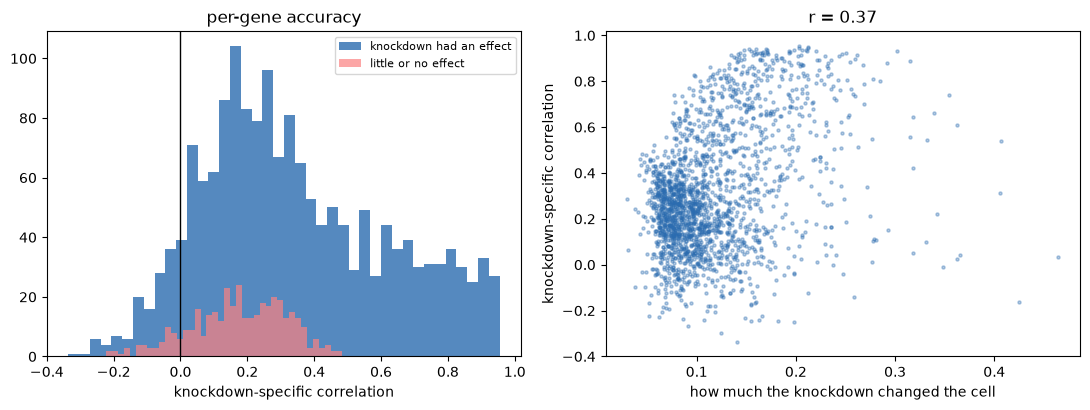

In [13]:
scores = per_gene['ensemble']
magnitude = np.abs(Y).mean(1)
aligned = scores.set_index('gene').loc[GENES].specific.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(scores[scores.responded].specific, bins=40, color='#2b6cb0', alpha=0.8,
             label='knockdown had an effect')
axes[0].hist(scores[~scores.responded].specific, bins=40, color='#fc8181', alpha=0.7,
             label='little or no effect')
axes[0].axvline(0, c='k', lw=1)
axes[0].legend(fontsize=8)
axes[0].set(xlabel='knockdown-specific correlation', title='per-gene accuracy')

axes[1].scatter(magnitude, aligned, s=5, alpha=0.35, color='#2b6cb0')
axes[1].set(xlabel='how much the knockdown changed the cell',
            ylabel='knockdown-specific correlation',
            title=f'r = {np.corrcoef(magnitude, aligned)[0, 1]:.2f}')
fig.tight_layout()
fig.savefig(FIGS / 'breakdown.png', dpi=150, bbox_inches='tight')

## Result

The ensemble reaches 0.345 against a 0.223 average-response baseline, and 0.313 on the
knockdown-specific component where that baseline scores 0 by construction. Two results cut
against expectation: the neural network barely beats ridge regression (consistent with
[Ahlmann-Eltze et al. 2025](https://doi.org/10.1038/s41592-025-02772-6)), and ESM-2 beats the
baseline on sequence alone yet adds nothing once GO and STRING are present.